**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [1]:
! pip install lightning torchmetrics torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 10.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 19.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lightning]


3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Human activity recognition

In this notebook, you will work on the [Human Activity Recognition](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) dataset.

This dataset was built from recordings of 30 subjects performing activities of daily living while wearing a waist-mounted smartphone equipped with inertial sensors.

Here is some additional information about the experiments conducted:

> The experiments were carried out with a group of 30 volunteers aged 19 to 48 years old. Each person performed six activities (*walking*, *walking upstairs*, *walking downstairs*, *sitting*, *standing*, *lying down*) wearing a smartphone (Samsung Galaxy S II) on the waist. Using the embedded accelerometer and gyroscope, they captured the linear acceleration and angular velocity along three axes at a constant rate of 50 Hz. The experiments were also video-recorded to label the data manually. The resulting dataset was randomly split into two sets, with 70% of the volunteers selected to generate the training data and 30% the evaluation data. The sensor signals (accelerometer and gyroscope) were preprocessed by applying noise filters, then sampled in fixed-width sliding windows of 2.56 seconds with 50% overlap (128 values per window).

**The goal is to predict the activity performed by the subject from the signals recorded by the sensor and then preprocessed.**

## (Down)loading the data, visualization, and preprocessing

The `load_dataset()` function defined below loads (and downloads if necessary) the dataset.

In [3]:
import torch


def load_dataset(train, path="data"):
    """Load the dataset.

    Parameters
    ----------
    train : bool
        If True, returns the training set. Otherwise, returns the validation set.

    path : str
        Path to the directory where the dataset is (down)loaded.

    Returns
    -------
    x : Tensor, shape = (n_samples, n_channels, n_points)
        Inputs.

    y : Tensor, shape = (n_samples,)
        Labels.

    subject : Tensor, shape = (n_samples,)
        Identifiers of the subjects.
    """
    import numpy as np
    import os
    import zipfile

    # Download the dataset if necessary
    if not os.path.isfile(os.path.join(
        path, "human+activity+recognition+using+smartphones.zip"
    )):
        from urllib.request import urlretrieve

        if not os.path.exists(path):
            os.makedirs(path)

        url = (
            "https://archive.ics.uci.edu/static/public/240/"
            "human+activity+recognition+using+smartphones.zip"
        )
        urlretrieve(url, os.path.join(
            path, "human+activity+recognition+using+smartphones.zip"
        ))

    if not os.path.isfile(os.path.join(path, "UCI HAR Dataset.zip")):
        with zipfile.ZipFile(
            os.path.join(path, "human+activity+recognition+using+smartphones.zip"), "r"
        ) as zip_ref:
            zip_ref.extractall(path)

    if not os.path.isdir(os.path.join(path, "UCI HAR Dataset")):
        with zipfile.ZipFile(os.path.join(path, "UCI HAR Dataset.zip"), "r") as zip_ref:
            zip_ref.extractall(path)

    set_ = "train" if train else "test"
    file_names = [
            f"body_acc_x_{set_}.txt", f"body_acc_y_{set_}.txt", f"body_acc_z_{set_}.txt",
            f"body_gyro_x_{set_}.txt", f"body_gyro_y_{set_}.txt", f"body_gyro_z_{set_}.txt",
            f"total_acc_x_{set_}.txt", f"total_acc_y_{set_}.txt", f"total_acc_z_{set_}.txt",
        ]

    # Input data
    x = np.asarray([
        np.loadtxt(os.path.join(
            path, "UCI HAR Dataset", set_, "Inertial Signals", file
        )) for file in file_names
    ])
    x = np.transpose(x, (1, 0, 2))

    # Output data
    y = np.loadtxt(os.path.join(path, "UCI HAR Dataset", set_, f"y_{set_}.txt"))

    # Subjects
    subjects = np.loadtxt(os.path.join(
        path, "UCI HAR Dataset", set_, f"subject_{set_}.txt"
    ), dtype="int64")

    # Convert to PyTorch tensors
    x = torch.from_numpy(x).to(dtype=torch.float32)
    y = torch.from_numpy(y - 1).to(dtype=torch.int64)
    subjects = torch.from_numpy(subjects).to(dtype=torch.int64)

    return x, y, subjects

Simply call this function to retrieve the training and validation sets.

In [4]:
x_train, y_train, subjects_train = load_dataset(train=True)
x_val, y_val, subjects_val = load_dataset(train=False)

For each dataset, we have 3 variables:

* `x` contains the inputs (i.e., the signals); it is a tensor of size `(n_samples, n_channels, n_points)`.
* `y` contains the outputs (i.e., the labels); it is a tensor of size `(n_samples,)`.
* `subjects` contains the subject identification (since several activities were recorded for each subject); it is a tensor of size `(n_samples,)`.

### Question 1

Determine the number of samples (`n_samples`) in the training and validation sets.
Determine the size of each input sample (`n_channels` and `n_points`).

In [8]:
print(f"The number of training samples is {x_train.shape[0]}")
print(f"The number of validation sample is {x_val.shape[0]}")

print(f"The dimension of each sample is {x_train.shape[1]} channels x {x_train.shape[2]} points")

The number of training samples is 7352
The number of validation sample is 2947
The dimension of each sample is 9 channels x 128 points


The `plot_sample()` function defined below displays a sample.

In [9]:
import matplotlib.pyplot as plt


def plot_sample(x, y, idx):
    """Plot the sample for the given index.

    Parameters
    ----------
    x : array, shape = (n_samples, n_channels, n_points)
        Input samples.

    y : array, shape = (n_samples)
        Target samples.

    idx : int
        Index of the sample to plot.
    """
    if not 0 <= idx < len(x):
        raise ValueError("The index is not valid.")

    label_mapping = {
        0: 'Walking',
        1: 'Walking upstairs',
        2: 'Walking downstairs',
        3: 'Sitting',
        4: 'Standing',
        5: 'Lying'
    }

    labels = [
        'Body acceleration - X',
        'Body acceleration - Y',
        'Body acceleration - Z',
        'Body gyroscope - X',
        'Body gyroscope - Y',
        'Body gyroscope - Z',
        'Total acceleration - X',
        'Total acceleration - Y',
        'Total acceleration - Z'
    ]

    for i, label in enumerate(labels):
        plt.plot(x[idx, i], label=label)
    plt.legend(bbox_to_anchor=(1., 1.))
    _ = plt.title(label_mapping[y[idx].item()])

### Question 2

Display a few samples from the training and validation sets using the `plot_sample()` function.

None

None

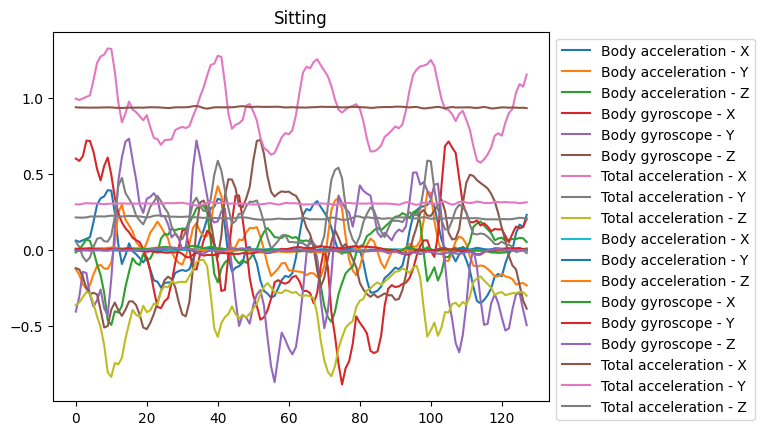

In [21]:
from numpy import random
samples_show_train = random.randint(low=0, high=x_train.shape[0], size=1)
samples_show_val = random.randint(low=0, high=x_train.shape[0], size=1)

plot_sample(x_val, y_val, samples_show_val[0])

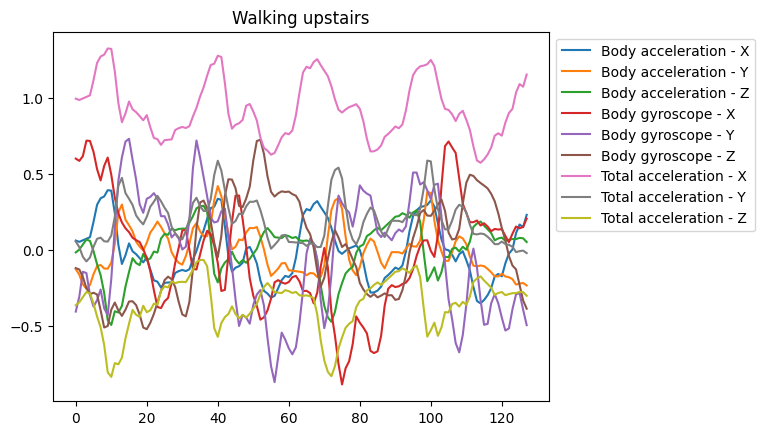

In [22]:
plot_sample(x_train, y_train, samples_show_train[0])

### Question 3

The goal of inference is to be able to identify the activities of new subjects (i.e., subjects that are not present in the training set).
Verify that the intersection between the set of subjects in the training set and the set of subjects in the validation set is empty.
To do this, you can use, in this order:

* the [`torch.unique()`](https://pytorch.org/docs/stable/generated/torch.unique.html) function, which returns the unique elements of a tensor,
* the [`torch.Tensor.tolist()`](https://pytorch.org/docs/stable/generated/torch.Tensor.tolist.html) method, which transforms a tensor into a list,
* the native [`set()`](https://docs.python.org/3/library/functions.html#func-set) function to create a set from a list,
* the `&` operator, which performs the intersection between two sets.

In [24]:
set(torch.unique(subjects_train).tolist()) & set(torch.unique(subjects_val).tolist())

set()

### Question 4

Compute the class distribution on the training and validation sets.
You can use the [`torch.bincount()`](https://pytorch.org/docs/stable/generated/torch.bincount.html) function.
Use these results to propose an appropriate classification metric.

In [28]:
print(torch.bincount(y_train))
print(torch.bincount(y_val))

tensor([1226, 1073,  986, 1286, 1374, 1407])
tensor([496, 471, 420, 491, 532, 537])


**Answer**: there is some imbalance among the classes, although not very extreme. Regular accuracy should still provide sensible results.

### Question 5

Create the training and validation *datasets* using the [`torch.utils.data.TensorDataset()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset) class, then the training and validation *dataloaders* using the [`torch.utils.data.DataLoader()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) class.
Use batches of size $32$ and do not forget to shuffle the samples for the training dataloader.

In [29]:
from torch.utils.data import TensorDataset, DataLoader

dataset_train = TensorDataset(x_train, y_train)
dataset_val = TensorDataset(x_val, y_val)

train = DataLoader(dataset_train, batch_size=32, shuffle=True)
val = DataLoader(dataset_val, batch_size=32, shuffle=False)

## Base class for classification

You will train several models with different architectures.
However, several operations will be identical for all these models.
This is why we will first define a base class with all the common operations.
The `BaseClass()` class defined below will contain these common operations.

### Question 6

Complete the missing code in the `__init__()`, `step()`, and `configure_optimizers()` methods of the `BaseClass()` class using the following information:
* `__init__()`: you need to define the loss function (`self.loss`) and the metrics for the training set (`self.metric_train`) and validation set (`self.metric_val`);
* `step()`: given a batch of samples (`batch`), you need to:
    + retrieve the inputs (`X`) and the labels (`y`),
    + compute the logits for these inputs (`logits`),
    + compute the loss function between the logits and the labels (`loss`),
    + compute the predicted class for each sample in the batch (`y_pred`).
* `configure_optimizers()`: we will use the [torch.optim.Adam()](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html) optimization algorithm with the default values for its hyperparameters.

In [88]:
import lightning as L
from torchmetrics import Accuracy



class BaseClass(L.LightningModule):

    def __init__(self):
        """Constructor."""
        super().__init__()  # Always run the constructor of the parent class

        ### BEGIN TODO ###
        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()

        # Instantiate the metrics
        self.metric_train = Accuracy(task="multiclass", num_classes=6)
        self.metric_val = Accuracy(task="multiclass", num_classes=6)
        #### END TODO ####

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        x, y = batch
        logits = self(x)
        loss = self.loss(logits, y)
        y_pred = logits.argmax(1)
        #### END TODO ###

        if dataset == "training":
            metric = self.metric_train
            name = "train"
            bar_step = True
        else:
            metric = self.metric_val
            name = "val"
            bar_step = False

        metric_score = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"metric_{name}", metric_score, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['metric_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['metric_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        ### BEGIN TODO ###
        optimizer = torch.optim.Adam(self.parameters())
        #### END TODO ####
        return optimizer

## Classification with a multilayer perceptron

Since the length of each signal is fixed ($128$) after data preprocessing, it is possible to use a multilayer perceptron.

You will implement a multilayer perceptron in the `MLP()` class defined below with the following sequential architecture:

* Flattening of the input sample to transform it into a one-dimensional tensor (a vector)
* Linear layer with 256 output variables
* ReLU activation function
* Dropout layer with a probability of $0.2$
* Linear layer with 64 output variables
* ReLU activation function
* Linear layer with 6 output variables

Here are the links to the documentation for the relevant classes:
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html),
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html), and
[`torch.nn.Dropout()`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html).

### Question 7

Complete the missing code in the `__init__()` and `forward()` methods of the `MLP()` class.
Display a summary of the architecture. How many trainable parameters does it have?

In [90]:
class MLP(BaseClass):

    def __init__(self):
        super().__init__()
        ### BEGIN TODO ###
        self.sequential = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(9*128, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(256, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64,6)
        )
        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        logits = self.sequential(x)
        #### END TODO ####
        return logits

In [91]:
from torchinfo import summary
summary(MLP(), input_size=(32,*(9,128)))

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [32, 6]                   --
├─Sequential: 1-1                        [32, 6]                   --
│    └─Flatten: 2-1                      [32, 1152]                --
│    └─Linear: 2-2                       [32, 256]                 295,168
│    └─ReLU: 2-3                         [32, 256]                 --
│    └─Dropout: 2-4                      [32, 256]                 --
│    └─Linear: 2-5                       [32, 64]                  16,448
│    └─ReLU: 2-6                         [32, 64]                  --
│    └─Linear: 2-7                       [32, 6]                   390
Total params: 312,006
Trainable params: 312,006
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 9.98
Input size (MB): 0.15
Forward/backward pass size (MB): 0.08
Params size (MB): 1.25
Estimated Total Size (MB): 1.48

**Answer**: There are 312006 trainable parameters

### Question 8

Train your model for $10$ epochs.

In [92]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_mlp = MLP()

trainer_mlp = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    callbacks=[TQDMProgressBar(refresh_rate=100)]
)

trainer_mlp.fit(
    model=model_mlp,
    train_dataloaders=train,
    val_dataloaders=val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 8



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.62263    | 76.7274% |
| Validation |    0.53584    | 83.4747% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.22921    | 91.2269% |
| Validation |    0.51111    | 87.2073% |
----------------------------------------- 



... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.11274    | 95.1578% |
| Validation |    0.52511    | 89.5148% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.11179    | 95.4026% |
| Validation |    0.63134    | 87.6485% |
----------------------------------------- 



## Classification with a convolutional neural network

Since the length of each signal is fixed ($128$) after data preprocessing and the data is sequential, it is also possible and relevant to use a convolutional neural network.

You will implement a convolutional neural network in the `CNN()` class defined below with the following sequential architecture:

* One-dimensional convolutional layer with $32$ output channels and a kernel of size $9$
* ReLU activation function
* One-dimensional pooling layer with a kernel and stride of size $2$
* One-dimensional convolutional layer with $64$ output channels and a kernel of size $9$
* ReLU activation function
* One-dimensional pooling layer with a kernel and stride of size $2$
* Flattening of the (two-dimensional) input to transform it into a one-dimensional tensor (a vector)
* Linear layer with $1664$ input variables and $256$ output variables
* ReLU activation function
* Linear layer with $6$ output variables

Here are the links to the documentation for the relevant classes:
[`torch.nn.Conv1d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[`torch.nn.MaxPool1d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool1d.html),
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html), and
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

### Question 9

Complete the missing code in the `__init__()` and `forward()` methods of the `CNN()` class.
Display a summary of the architecture. How many trainable parameters does it have?

In [98]:
class CNN(BaseClass):

    def __init__(self):
        super().__init__()
        ### BEGIN TODO ###
        self.sequential = torch.nn.Sequential(
            torch.nn.Conv1d(9, 32, 9),
            torch.nn.ReLU(),
            torch.nn.MaxPool1d(2, 2),
            torch.nn.Conv1d(32, 64, 9),
            torch.nn.ReLU(),
            torch.nn.MaxPool1d(2,2),
            torch.nn.Flatten(),
            torch.nn.Linear(1664, 256),
            torch.nn.ReLU(),
            torch.nn.Linear(256, 6)
        )
        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        logits = self.sequential(x)
        #### END TODO ####
        return logits

In [100]:
summary(CNN(), input_size=(32, *(9, 128)))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 6]                   --
├─Sequential: 1-1                        [32, 6]                   --
│    └─Conv1d: 2-1                       [32, 32, 120]             2,624
│    └─ReLU: 2-2                         [32, 32, 120]             --
│    └─MaxPool1d: 2-3                    [32, 32, 60]              --
│    └─Conv1d: 2-4                       [32, 64, 52]              18,496
│    └─ReLU: 2-5                         [32, 64, 52]              --
│    └─MaxPool1d: 2-6                    [32, 64, 26]              --
│    └─Flatten: 2-7                      [32, 1664]                --
│    └─Linear: 2-8                       [32, 256]                 426,240
│    └─ReLU: 2-9                         [32, 256]                 --
│    └─Linear: 2-10                      [32, 6]                   1,542
Total params: 448,902
Trainable params: 448,902
Non-trainable params: 

**Answer**: 448902 trainable parameters

### Question 10

Train your model for $10$ epochs.

In [101]:
cnn_model = CNN()

cnn_trainer = L.Trainer(
    max_epochs=10,
    logger=CSVLogger('.'),
    enable_model_summary=False,
    callbacks=[TQDMProgressBar(100)],
    num_sanity_val_steps=0
)

cnn_trainer.fit(cnn_model,
                train_dataloaders=train,
                val_dataloaders=val)

Training: |          | 0/? [00:00<?, ?it/s]

Version 9



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.41967    | 83.4603% |
| Validation |    0.44762    | 85.0696% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.14832    | 93.8112% |
| Validation |    0.28902    | 90.9739% |
----------------------------------------- 



... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.10219    | 95.4706% |
| Validation |    0.22548    | 92.1955% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.09579    | 95.7563% |
| Validation |    0.24300    | 91.6186% |
----------------------------------------- 



## Classification with a recurrent neural network

Since the data is sequential, it is also possible and relevant to use a recurrent neural network.

You will implement a recurrent neural network in the `RNN()` class defined below with the following sequential architecture:

* **Bidirectional** LSTM-type recurrent layer with $256$ variables for each hidden state
* Linear layer with 6 output variables

Here are the links to the documentation for the relevant classes:
[`torch.nn.LSTM()`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html) and
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

### Question 11

Complete the missing code in the `__init__()` and `forward()` methods of the `RNN()` class.
Display a summary of the architecture. How many trainable parameters does it have?

In [122]:
class RNN(BaseClass):

    def __init__(self):
        super().__init__()
        ### BEGIN TODO ###
        self.lstm = torch.nn.LSTM(9, 256, bidirectional=True, batch_first=True)
        self.linear = torch.nn.Linear(512, 6)
        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        x = torch.transpose(x, 1, 2)
        _, (h_n, _) = self.lstm(x)
        h_n = torch.nn.Flatten()(torch.transpose(h_n, 0, 1))
        logits = self.linear(h_n)
        #### END TODO ####
        return logits

In [123]:
summary(RNN(), input_size=(32, *(9, 128)))

Layer (type:depth-idx)                   Output Shape              Param #
RNN                                      [32, 6]                   --
├─LSTM: 1-1                              [32, 128, 512]            546,816
├─Linear: 1-2                            [32, 6]                   3,078
Total params: 549,894
Trainable params: 549,894
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 2.24
Input size (MB): 0.15
Forward/backward pass size (MB): 16.78
Params size (MB): 2.20
Estimated Total Size (MB): 19.13

**Answer**: 549,894

### Question 12

Train your model for $10$ epochs.

In [ ]:
rnn_model = RNN()

rnn_trainer = L.Trainer(
    max_epochs=10,
    logger=CSVLogger('.'),
    enable_model_summary=False,
    callbacks=[TQDMProgressBar(100)],
    num_sanity_val_steps=0
)

rnn_trainer.fit(rnn_model,
                train_dataloaders=train,
                val_dataloaders=val)

Training: |          | 0/? [00:00<?, ?it/s]

Version 12



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.27707    | 44.7497% |
| Validation |    1.10882    | 54.6658% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.16486    | 49.8640% |
| Validation |    1.30549    | 48.2185% |
----------------------------------------- 



... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 5 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.13972    | 52.5843% |
| Validation |    1.35818    | 44.0448% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 6 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.14417    | 54.1349% |
| Validation |    1.40547    | 33.8649% |
----------------------------------------- 



### Question 13

Finally, which of your three models is the best? Justify your answer.

**Answer**: The CNN is the best, based on the performance it has on the validation set.